<a href="https://colab.research.google.com/github/bvsvntv/ai-ml-learning/blob/main/notebooks/lang-graph/stm_summarization.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [126]:
!pip install -U langchain-openai

In [127]:
from langgraph.graph import StateGraph, END, START, MessagesState
from langgraph.checkpoint.memory import InMemorySaver
from langchain_openai import ChatOpenAI
from langchain_core.messages import HumanMessage, RemoveMessage, AIMessage
from google.colab import userdata
from IPython.display import Image

In [128]:
api_key = userdata.get("OPENAI_API_KEY")
model = ChatOpenAI(api_key=api_key, model="gpt-6-luna")

In [129]:
# chat state
class ChatState(MessagesState):
  summary: str

In [130]:
def summarize_conversation(state: ChatState):
  existing_summary = state["summary"]

  # build summarization prompt
  if existing_summary:
    prompt=(
        f"Existing summary:\n{existing_summary}\n\n"
        "Extend the summary with new conversation above."
    )
  else:
    prompt = "Summarize the conversation above."

  messages_for_summary = state["messages"] + [HumanMessage(content=prompt)]

  response = model.invoke(messages_for_summary)

  # keep only last 2 messages verbatim
  messages_to_delete = state["messages"][:-2]
  cleaned_messages = [RemoveMessage(id=m.id) for m in messages_to_delete]

  return {
      "summary": response.content,
      "messages": cleaned_messages
  }

In [131]:
def chat_node(state: ChatState):
  messages = []

  summary = state["summary"]
  if summary:
    messages.append({
        "role": "system",
        "content": f"Conversation summary:\n{summary}"
    })

  messages.extend(state["messages"])

  print("-"*80)
  for m in messages:
    print(type(m).__name__, ":", m.content)
  print("-"*80)

  response = model.invoke(messages)
  return {"messages": [response]}

In [132]:
# Summarize after 10 messages
def should_summarize(state: ChatState):
  return len(state["messages"]) > 10

In [133]:
# graph
graph = StateGraph(ChatState)

graph.add_node("chat_node", chat_node)
graph.add_node("summarize_node", summarize_conversation)

graph.add_edge(START, "chat_node")
graph.add_conditional_edges("chat_node", should_summarize, {True: "summarize_node", False: END})
graph.add_edge("summarize_node", END)

In [134]:
checkpointer = InMemorySaver()
workflow = graph.compile(checkpointer=checkpointer)

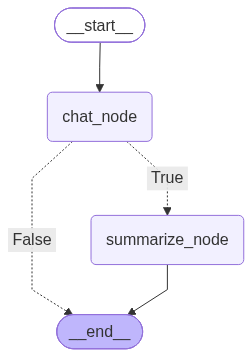

In [135]:
# view graph
Image(workflow.get_graph().draw_mermaid_png())

In [136]:
config = {"configurable": {"thread_id": "thread-1"}}

In [137]:
def run_turn(input: str):
  output = workflow.invoke({"messages": [HumanMessage(content=input)], "summary": ""}, config=config)
  return output

In [138]:
def view_state():
  graph_state = workflow.get_state(config)
  values = graph_state.values

  print("-"*35, "STATE", "-"*35)
  print("SUMMARY: ", values.get("summary", "No summary of conversation found."))
  print("NO. OF MESSAGES: ", len(values.get("messages", [])))
  print("MESSAGES:")
  for m in values.get("messages", []):
    print(type(m).__name__, ":", m.content)
  print("-"*80)

In [139]:
run_turn("I am planning a 10-day trip to Japan in April next year.")
view_state()

--------------------------------------------------------------------------------
HumanMessage : I am planning a 10-day trip to Japan in April next year.
--------------------------------------------------------------------------------
----------------------------------- STATE -----------------------------------
SUMMARY:  
NO. OF MESSAGES:  2
MESSAGES:
HumanMessage : I am planning a 10-day trip to Japan in April next year.
AIMessage : Great—April 2027 can be a lovely time to visit, though cherry-blossom dates vary by region and year.

For a first 10-day trip, a good starting route is **Tokyo (4 nights) → Kyoto (4 nights) → Osaka (1–2 nights)**, with a day trip to Nara or Hakone depending on your interests.

To tailor it, what are your:
- Exact travel dates and arrival/departure airports?
- Main interests (food, history, nature, anime, shopping, blossoms)?
- Preferred pace and rough budget?
- Any must-see places—or is this your first visit to Japan?
---------------------------------------

In [140]:
run_turn("My budget is around $3,000, excluding international flights.")
view_state()

--------------------------------------------------------------------------------
HumanMessage : I am planning a 10-day trip to Japan in April next year.
AIMessage : Great—April 2027 can be a lovely time to visit, though cherry-blossom dates vary by region and year.

For a first 10-day trip, a good starting route is **Tokyo (4 nights) → Kyoto (4 nights) → Osaka (1–2 nights)**, with a day trip to Nara or Hakone depending on your interests.

To tailor it, what are your:
- Exact travel dates and arrival/departure airports?
- Main interests (food, history, nature, anime, shopping, blossoms)?
- Preferred pace and rough budget?
- Any must-see places—or is this your first visit to Japan?
HumanMessage : My budget is around $3,000, excluding international flights.
--------------------------------------------------------------------------------
----------------------------------- STATE -----------------------------------
SUMMARY:  
NO. OF MESSAGES:  4
MESSAGES:
HumanMessage : I am planning a 10-d

In [141]:
run_turn("I love Japanese food, anime, historical places, and nature.")
view_state()

--------------------------------------------------------------------------------
HumanMessage : I am planning a 10-day trip to Japan in April next year.
AIMessage : Great—April 2027 can be a lovely time to visit, though cherry-blossom dates vary by region and year.

For a first 10-day trip, a good starting route is **Tokyo (4 nights) → Kyoto (4 nights) → Osaka (1–2 nights)**, with a day trip to Nara or Hakone depending on your interests.

To tailor it, what are your:
- Exact travel dates and arrival/departure airports?
- Main interests (food, history, nature, anime, shopping, blossoms)?
- Preferred pace and rough budget?
- Any must-see places—or is this your first visit to Japan?
HumanMessage : My budget is around $3,000, excluding international flights.
AIMessage : Assuming you mean **US$3,000 for one person**, excluding international flights, that’s workable for 10 days in Japan—especially if you choose modest hotels and keep shopping limited. **April is a popular, often expensive mo

In [142]:
run_turn("I will be travelling with my younger brother. We both enjoy photography.")
view_state()

--------------------------------------------------------------------------------
HumanMessage : I am planning a 10-day trip to Japan in April next year.
AIMessage : Great—April 2027 can be a lovely time to visit, though cherry-blossom dates vary by region and year.

For a first 10-day trip, a good starting route is **Tokyo (4 nights) → Kyoto (4 nights) → Osaka (1–2 nights)**, with a day trip to Nara or Hakone depending on your interests.

To tailor it, what are your:
- Exact travel dates and arrival/departure airports?
- Main interests (food, history, nature, anime, shopping, blossoms)?
- Preferred pace and rough budget?
- Any must-see places—or is this your first visit to Japan?
HumanMessage : My budget is around $3,000, excluding international flights.
AIMessage : Assuming you mean **US$3,000 for one person**, excluding international flights, that’s workable for 10 days in Japan—especially if you choose modest hotels and keep shopping limited. **April is a popular, often expensive mo

In [143]:
run_turn("I want to visit Tokyo, Kyoto, and Osaka. I would also like to see Mount Fuji.")
view_state()

--------------------------------------------------------------------------------
HumanMessage : I am planning a 10-day trip to Japan in April next year.
AIMessage : Great—April 2027 can be a lovely time to visit, though cherry-blossom dates vary by region and year.

For a first 10-day trip, a good starting route is **Tokyo (4 nights) → Kyoto (4 nights) → Osaka (1–2 nights)**, with a day trip to Nara or Hakone depending on your interests.

To tailor it, what are your:
- Exact travel dates and arrival/departure airports?
- Main interests (food, history, nature, anime, shopping, blossoms)?
- Preferred pace and rough budget?
- Any must-see places—or is this your first visit to Japan?
HumanMessage : My budget is around $3,000, excluding international flights.
AIMessage : Assuming you mean **US$3,000 for one person**, excluding international flights, that’s workable for 10 days in Japan—especially if you choose modest hotels and keep shopping limited. **April is a popular, often expensive mo

In [144]:
run_turn("I prefer travelling by train and staying in budget-friendly hotels.")
view_state()

--------------------------------------------------------------------------------
HumanMessage : I am planning a 10-day trip to Japan in April next year.
AIMessage : Great—April 2027 can be a lovely time to visit, though cherry-blossom dates vary by region and year.

For a first 10-day trip, a good starting route is **Tokyo (4 nights) → Kyoto (4 nights) → Osaka (1–2 nights)**, with a day trip to Nara or Hakone depending on your interests.

To tailor it, what are your:
- Exact travel dates and arrival/departure airports?
- Main interests (food, history, nature, anime, shopping, blossoms)?
- Preferred pace and rough budget?
- Any must-see places—or is this your first visit to Japan?
HumanMessage : My budget is around $3,000, excluding international flights.
AIMessage : Assuming you mean **US$3,000 for one person**, excluding international flights, that’s workable for 10 days in Japan—especially if you choose modest hotels and keep shopping limited. **April is a popular, often expensive mo

In [145]:
run_turn("I am particularly interested in visiting the Fushimi Inari Shrine in Kyoto.")
view_state()

--------------------------------------------------------------------------------
HumanMessage : I prefer travelling by train and staying in budget-friendly hotels.
AIMessage : That’s a good fit for Japan. I’d keep Tokyo as your base for the Fuji visit, then travel by train to Kyoto and Osaka.

### 10-day plan

- **Days 1–4: Tokyo — 4 nights**  
  Explore Asakusa and Senso-ji, visit anime shops in Akihabara or Ikebukuro, and take a day trip to **Kawaguchiko** for Mount Fuji views.
- **Days 5–7: Kyoto — 3 nights**  
  See Fushimi Inari, Higashiyama and Kiyomizu-dera, and Arashiyama. Early starts help with both photos and crowds.
- **Day 8: Nara, then Osaka**  
  Take a day trip to Nara, then continue to Osaka for the night. You could leave larger bags at your Kyoto hotel or send them ahead to Osaka.
- **Day 9: Osaka — 1 more night**  
  Explore Osaka Castle, Nipponbashi, and Dotonbori.
- **Day 10: Depart from Osaka**, if your flights allow.

### Train tips

- For Fuji, take the **Fuji Ex

In [146]:
run_turn("I also want to try authentic ramen, sushi, and Japanese street food.")
view_state()

--------------------------------------------------------------------------------
HumanMessage : I prefer travelling by train and staying in budget-friendly hotels.
AIMessage : That’s a good fit for Japan. I’d keep Tokyo as your base for the Fuji visit, then travel by train to Kyoto and Osaka.

### 10-day plan

- **Days 1–4: Tokyo — 4 nights**  
  Explore Asakusa and Senso-ji, visit anime shops in Akihabara or Ikebukuro, and take a day trip to **Kawaguchiko** for Mount Fuji views.
- **Days 5–7: Kyoto — 3 nights**  
  See Fushimi Inari, Higashiyama and Kiyomizu-dera, and Arashiyama. Early starts help with both photos and crowds.
- **Day 8: Nara, then Osaka**  
  Take a day trip to Nara, then continue to Osaka for the night. You could leave larger bags at your Kyoto hotel or send them ahead to Osaka.
- **Day 9: Osaka — 1 more night**  
  Explore Osaka Castle, Nipponbashi, and Dotonbori.
- **Day 10: Depart from Osaka**, if your flights allow.

### Train tips

- For Fuji, take the **Fuji Ex

In [147]:
run_turn("Can you suggest a day-by-day itinerary that fits my budget and interests?")
view_state()

--------------------------------------------------------------------------------
HumanMessage : I prefer travelling by train and staying in budget-friendly hotels.
AIMessage : That’s a good fit for Japan. I’d keep Tokyo as your base for the Fuji visit, then travel by train to Kyoto and Osaka.

### 10-day plan

- **Days 1–4: Tokyo — 4 nights**  
  Explore Asakusa and Senso-ji, visit anime shops in Akihabara or Ikebukuro, and take a day trip to **Kawaguchiko** for Mount Fuji views.
- **Days 5–7: Kyoto — 3 nights**  
  See Fushimi Inari, Higashiyama and Kiyomizu-dera, and Arashiyama. Early starts help with both photos and crowds.
- **Day 8: Nara, then Osaka**  
  Take a day trip to Nara, then continue to Osaka for the night. You could leave larger bags at your Kyoto hotel or send them ahead to Osaka.
- **Day 9: Osaka — 1 more night**  
  Explore Osaka Castle, Nipponbashi, and Dotonbori.
- **Day 10: Depart from Osaka**, if your flights allow.

### Train tips

- For Fuji, take the **Fuji Ex

In [148]:
run_turn("Can you remind me who I am travelling with, my budget, and which places I wanted to visit?")
view_state()

--------------------------------------------------------------------------------
HumanMessage : I prefer travelling by train and staying in budget-friendly hotels.
AIMessage : That’s a good fit for Japan. I’d keep Tokyo as your base for the Fuji visit, then travel by train to Kyoto and Osaka.

### 10-day plan

- **Days 1–4: Tokyo — 4 nights**  
  Explore Asakusa and Senso-ji, visit anime shops in Akihabara or Ikebukuro, and take a day trip to **Kawaguchiko** for Mount Fuji views.
- **Days 5–7: Kyoto — 3 nights**  
  See Fushimi Inari, Higashiyama and Kiyomizu-dera, and Arashiyama. Early starts help with both photos and crowds.
- **Day 8: Nara, then Osaka**  
  Take a day trip to Nara, then continue to Osaka for the night. You could leave larger bags at your Kyoto hotel or send them ahead to Osaka.
- **Day 9: Osaka — 1 more night**  
  Explore Osaka Castle, Nipponbashi, and Dotonbori.
- **Day 10: Depart from Osaka**, if your flights allow.

### Train tips

- For Fuji, take the **Fuji Ex